In [3]:
#Import the libraries  
import pandas as pd 
import numpy as np 
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.metrics import r2_score, mean_absolute_error

In [41]:
#Load the clean files 
Financial_facts_clean=pd.read_csv("Financial_facts_cleaned.csv")
fillings_clean=pd.read_csv("fillings_cleaned_data.csv")

In [44]:
#Basic analysis and inspection for Financial_facts_clean
print("==Financial_facts_clean==")
print(Financial_facts_clean.head())
print(Financial_facts_clean.shape)
print(Financial_facts_clean.columns)
print(Financial_facts_clean.dtypes)
print(Financial_facts_clean.info())
print(Financial_facts_clean.describe())

==Financial_facts_clean==
  taxonomy                             concept  \
0      dei  EntityCommonStockSharesOutstanding   
1      dei                   EntityPublicFloat   
2  us-gaap                     AccountsPayable   
3  us-gaap                     AccountsPayable   
4  us-gaap        AccountsReceivableNetCurrent   

                                               label  \
0            Entity Common Stock, Shares Outstanding   
1                                Entity Public Float   
2           Accounts Payable (Deprecated 2009-01-31)   
3           Accounts Payable (Deprecated 2009-01-31)   
4  Accounts Receivable, after Allowance for Credi...   

                                         description    unit         value  \
0  Indicate number of shares or other units outst...  shares  8.958168e+08   
1  The aggregate market value of the voting and n...     USD  9.459300e+10   
2  Carrying value as of the balance sheet date of...     USD  5.520000e+09   
3  Carrying value as of 

In [8]:
#Basic analysis and inspection for fillings_clean

print("==fillings_clean==")
print(fillings_clean.head())
print(fillings_clean.shape)
print(fillings_clean.columns)
print(fillings_clean.dtypes)
print(fillings_clean.info())
print(fillings_clean.describe())

==fillings_clean==
        accessionnumber  filingdate  reportdate form  \
0  0001958244-26-000636  2026-10-02  2015-10-01  144   
1  0001959173-26-007235  2026-10-02  2015-10-01  144   
2  0001969223-26-001055  2026-10-02  2015-10-01  144   
3  0001140361-26-038307  2026-10-01  2026-09-29    4   
4  0001140361-26-038028  2026-09-29  2026-09-27    4   

             primarydocument primarydocdescription      items  size  isxbrl  \
0  xsl144X01/primary_doc.xml                FORM 4  2.02,9.01  5383       0   
1  xsl144X01/primary_doc.xml                FORM 4  2.02,9.01  5724       0   
2  xsl144X01/primary_doc.xml                FORM 4  2.02,9.01  4440       0   
3       xslF345X06/form4.xml                FORM 4  2.02,9.01  4822       0   
4       xslF345X06/form4.xml                FORM 4  2.02,9.01  8159       0   

   isinlinexbrl        acceptancedatetime  
0             0  2026-10-02T21:17:10.000Z  
1             0  2026-10-02T20:20:06.000Z  
2             0  2026-10-02T20:09:51.

In [17]:
# Profitability trends
profitability = Financial_facts_clean[
    Financial_facts_clean["concept"].isin([
        "GrossProfit",
        "NetIncomeLoss",
        "CostOfGoodsAndServicesSold"
    ])
]

print(
    profitability[
        ["concept", "unit", "fy", "fp", "start", "end", "value"]
    ].sort_values(["fy", "concept", "end"]).to_string(index=False)
)

                   concept unit     fy fp      start        end        value
CostOfGoodsAndServicesSold  USD 2009.0 FY 2006-10-01 2007-09-29 1.585200e+10
CostOfGoodsAndServicesSold  USD 2009.0 FY 2006-10-01 2007-09-29 1.642600e+10
CostOfGoodsAndServicesSold  USD 2009.0 Q3 2007-09-30 2008-06-28 1.617800e+10
CostOfGoodsAndServicesSold  USD 2009.0 Q3 2008-03-30 2008-06-28 4.864000e+09
CostOfGoodsAndServicesSold  USD 2009.0 FY 2007-09-30 2008-09-27 2.133400e+10
CostOfGoodsAndServicesSold  USD 2009.0 FY 2007-09-30 2008-09-27 2.429400e+10
CostOfGoodsAndServicesSold  USD 2009.0 Q3 2008-09-28 2009-06-27 1.714100e+10
CostOfGoodsAndServicesSold  USD 2009.0 Q3 2009-03-29 2009-06-27 5.314000e+09
CostOfGoodsAndServicesSold  USD 2009.0 FY 2008-09-28 2009-09-26 2.339700e+10
CostOfGoodsAndServicesSold  USD 2009.0 FY 2008-09-28 2009-09-26 2.568300e+10
               GrossProfit  USD 2009.0 FY 2006-10-01 2007-09-29 8.154000e+09
               GrossProfit  USD 2009.0 FY 2006-10-01 2007-09-29 8.152000e+09

In [21]:
# Balance sheet health
# Select balance-sheet concepts
balance_data = Financial_facts_clean[
    Financial_facts_clean["concept"].isin([
        "StockholdersEquity",
        "AccountsPayableCurrent",
        "AccountsReceivableNetCurrent",
        "AssetsCurrent",
        "LiabilitiesCurrent",
        "LongTermDebtCurrent",
        "LongTermDebtNoncurrent"
    ])
].copy()

# Keep annual 10-K observations
balance_data = balance_data[
    (balance_data["form"] == "10-K") &
    (balance_data["fp"] == "FY") &
    (balance_data["unit"] == "USD")
].copy()

# Create year
balance_data["year"] = pd.to_datetime(
    balance_data["end"]
).dt.year

# Remove duplicate observations
balance_data = (
    balance_data
    .sort_values(["concept", "end", "filed"])
    .drop_duplicates(["concept", "end"], keep="last")
)

# Convert from long to wide format
balance = balance_data.pivot(
    index="year",
    columns="concept",
    values="value"
).sort_index()

# Calculate ratios
balance["WorkingCapital"] = (
    balance["AssetsCurrent"] -
    balance["LiabilitiesCurrent"]
)

balance["CurrentRatio"] = (
    balance["AssetsCurrent"] /
    balance["LiabilitiesCurrent"]
)

balance["TotalDebt"] = (
    balance["LongTermDebtCurrent"].fillna(0) +
    balance["LongTermDebtNoncurrent"].fillna(0)
)

balance["DebtToEquity"] = (
    balance["TotalDebt"] /
    balance["StockholdersEquity"]
)

print(balance.round(2))

concept  AccountsPayableCurrent  AccountsReceivableNetCurrent  AssetsCurrent  \
year                                                                           
2006                        NaN                           NaN            NaN   
2007                        NaN                           NaN            NaN   
2008               5.520000e+09                  2.422000e+09   3.231100e+10   
2009               5.601000e+09                  3.361000e+09   3.155500e+10   
2010               1.201500e+10                  5.510000e+09   4.167800e+10   
2011               1.463200e+10                  5.369000e+09   4.498800e+10   
2012               2.117500e+10                  1.093000e+10   5.765300e+10   
2013               2.236700e+10                  1.310200e+10   7.328600e+10   
2014               3.019600e+10                  1.746000e+10   6.853100e+10   
2015               3.549000e+10                  1.684900e+10   8.937800e+10   
2016               3.729400e+10         

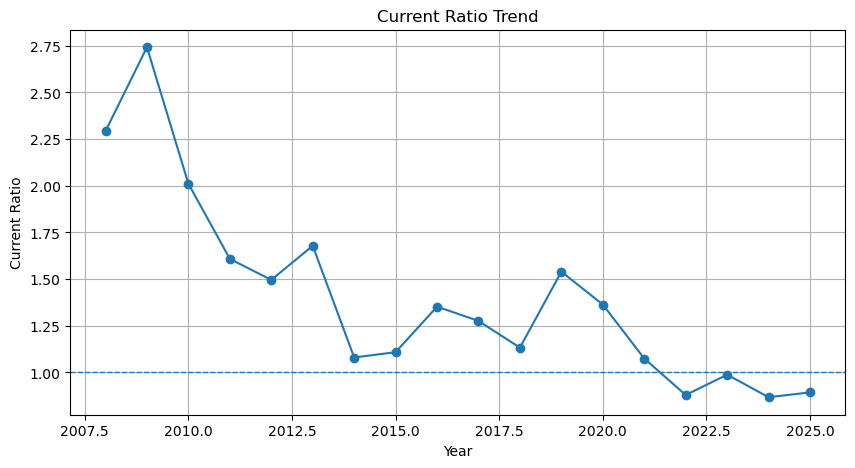

In [22]:
plt.figure(figsize=(10, 5))

plt.plot(
    balance.index,
    balance["CurrentRatio"],
    marker="o"
)

plt.axhline(1, linestyle="--", linewidth=1)

plt.title("Current Ratio Trend")
plt.xlabel("Year")
plt.ylabel("Current Ratio")
plt.grid(True)

plt.show()

In [23]:
#Market size / company valuation
market_size = Financial_facts_clean[
    Financial_facts_clean["concept"] == "EntityPublicFloat"
].copy()

market_size["year"] = pd.to_datetime(
    market_size["end"]
).dt.year

market_size = (
    market_size
    .sort_values(["end", "filed"])
    .drop_duplicates("end", keep="last")
)

print(
    market_size[
        ["year", "end", "value", "unit"]
    ].sort_values("year")
)

       year         end         value unit
386    2009  2009-03-28  9.459300e+10  USD
1265   2010  2010-03-27  2.085650e+11  USD
2759   2011  2011-03-25  3.229210e+11  USD
4180   2012  2012-03-30  5.603560e+11  USD
6234   2013  2013-03-29  4.160050e+11  USD
7882   2014  2014-03-28  4.625220e+11  USD
10068  2015  2015-03-27  7.099230e+11  USD
11598  2016  2016-03-25  5.788070e+11  USD
13153  2017  2017-03-31  7.475090e+11  USD
14692  2018  2018-03-30  8.288800e+11  USD
16183  2019  2019-03-29  8.746980e+11  USD
17713  2020  2020-03-27  1.070633e+12  USD
19167  2021  2021-03-26  2.021360e+12  USD
20447  2022  2022-03-25  2.830067e+12  USD
21677  2023  2023-03-31  2.591165e+12  USD
22829  2024  2024-03-29  2.628553e+12  USD
23950  2025  2025-03-28  3.253431e+12  USD


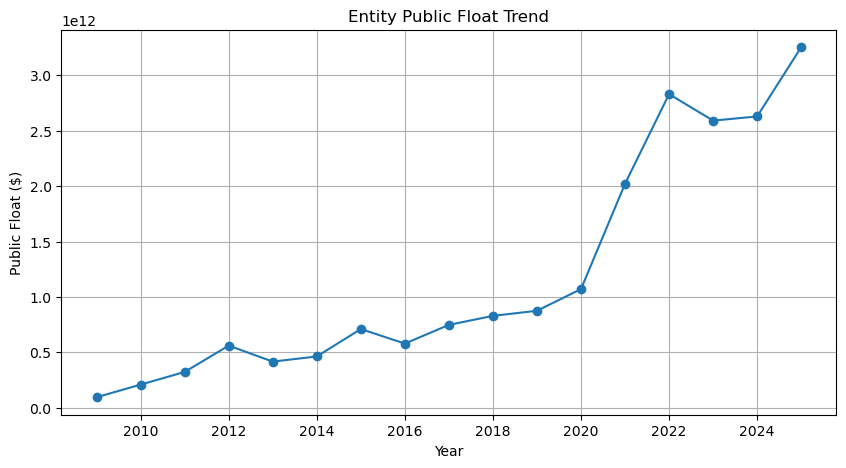

In [25]:
plt.figure(figsize=(10, 5))

plt.plot(
    market_size["year"],
    market_size["value"],
    marker="o"
)

plt.title("Entity Public Float Trend")
plt.xlabel("Year")
plt.ylabel("Public Float ($)")
plt.grid(True)

plt.show()

In [24]:
#Find the non-dollar operating metrics 
operating_metrics = Financial_facts_clean[
    ~Financial_facts_clean["unit"].isin(["USD", "USD/shares"])
].copy()

print(
    operating_metrics[
        ["concept", "label", "unit", "fy", "value"]
    ].sort_values(["unit", "concept"])
)

                                             concept  \
8957                                  NumberOfStores   
9508                                  NumberOfStores   
9886                                  NumberOfStores   
10397                                 NumberOfStores   
10772                                 NumberOfStores   
...                                              ...   
24851  WeightedAverageNumberOfSharesOutstandingBasic   
25131  WeightedAverageNumberOfSharesOutstandingBasic   
25132  WeightedAverageNumberOfSharesOutstandingBasic   
25133  WeightedAverageNumberOfSharesOutstandingBasic   
25134  WeightedAverageNumberOfSharesOutstandingBasic   

                                                   label    unit      fy  \
8957                                    Number of Stores   Store  2015.0   
9508                                    Number of Stores   Store  2015.0   
9886                                    Number of Stores   Store  2015.0   
10397                  

In [32]:
#Insider activity
print("==Insider-related forms==")
insider = fillings_clean[
    fillings_clean["form"].isin([
        "3", "3/A",
        "4", "4/A",
        "5",
        "144", "144/A"
    ])
].copy()

# Count filings by form
insider_counts = (
    insider["form"]
    .value_counts()
    .sort_index()
)

print(insider_counts)


print("==Count filings by form==")
insider_counts = (
    insider["form"]
    .value_counts()
    .sort_index()
)

print(insider_counts)

==Insider-related forms==
form
144       49
144/A      1
3         12
3/A        1
4        594
4/A        1
5          1
Name: count, dtype: int64
==Count filings by form==
form
144       49
144/A      1
3         12
3/A        1
4        594
4/A        1
5          1
Name: count, dtype: int64


Correlation Matrix:
concept                                               Assets  \
concept                                                        
Assets                                              1.000000   
CashAndCashEquivalentsAtCarryingValue               0.898667   
Liabilities                                         0.964787   
NetIncomeLoss                                       0.695710   
PaymentsOfDividends                                 0.693821   
RevenueFromContractWithCustomerExcludingAssesse...  0.507547   
Revenues                                            0.977400   
StockholdersEquity                                  0.835271   

concept                                             CashAndCashEquivalentsAtCarryingValue  \
concept                                                                                     
Assets                                                                           0.898667   
CashAndCashEquivalentsAtCarryingValue                       

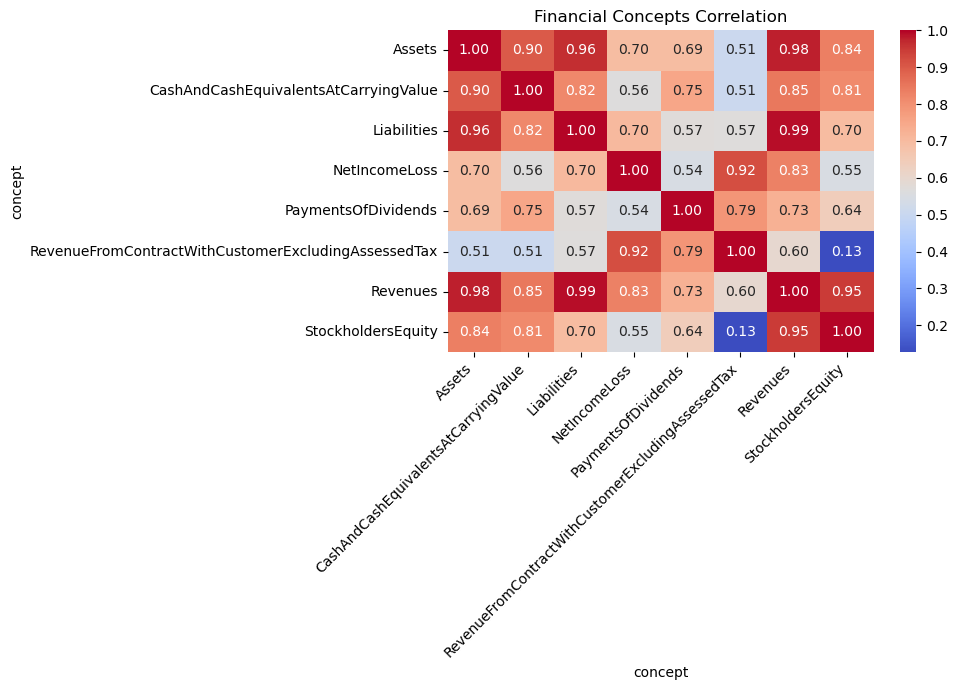

In [43]:


# Load the data
df = pd.read_csv("Financial_facts_cleaned.csv")

# Financial concepts we want to analyze
concepts = [
    "Revenues",
    "RevenueFromContractWithCustomerExcludingAssessedTax",
    "NetIncomeLoss",
    "Assets",
    "Liabilities",
    "StockholdersEquity",
    "CashAndCashEquivalentsAtCarryingValue",
    "PaymentsOfDividends"
]

# Keep only the selected concepts
df = df[df["concept"].isin(concepts)].copy()

# Convert date column
df["end"] = pd.to_datetime(df["end"], errors="coerce")

# Convert values to numbers
df["value"] = pd.to_numeric(df["value"], errors="coerce")

# Remove missing values
df = df.dropna(subset=["end", "value"])

# Create a table with concepts as columns
correlation_data = df.pivot_table(
    index="end",
    columns="concept",
    values="value",
    aggfunc="sum"
)

# Calculate correlation
correlation = correlation_data.corr()

# Display correlation table
print("Correlation Matrix:")
print(correlation)

# Create heatmap
plt.figure(figsize=(10, 7))

sns.heatmap(
    correlation,
    annot=True,
    cmap="coolwarm",
    fmt=".2f"
)

plt.title("Financial Concepts Correlation")
plt.xticks(rotation=45, ha="right")
plt.yticks(rotation=0)
plt.tight_layout()
plt.show()